In [1]:
import numpy as np
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pulse_vqe_entanglement.dataclasses import SimulationConfig
from pulse_vqe_entanglement.optimisation import SQEOptimisation
from pulse_vqe_entanglement.plotting import plot_optimisation_results

Tracing control amplitude graph.

Total iterations: 24
I_final = 8.955800e-07  (threshold 1.0e-06)
||grad|| = 2.565014e-06  (final gtol 1.0e-08, min 1.0e-08)
RESULT: SUCCESS - Infidelity threshold reached



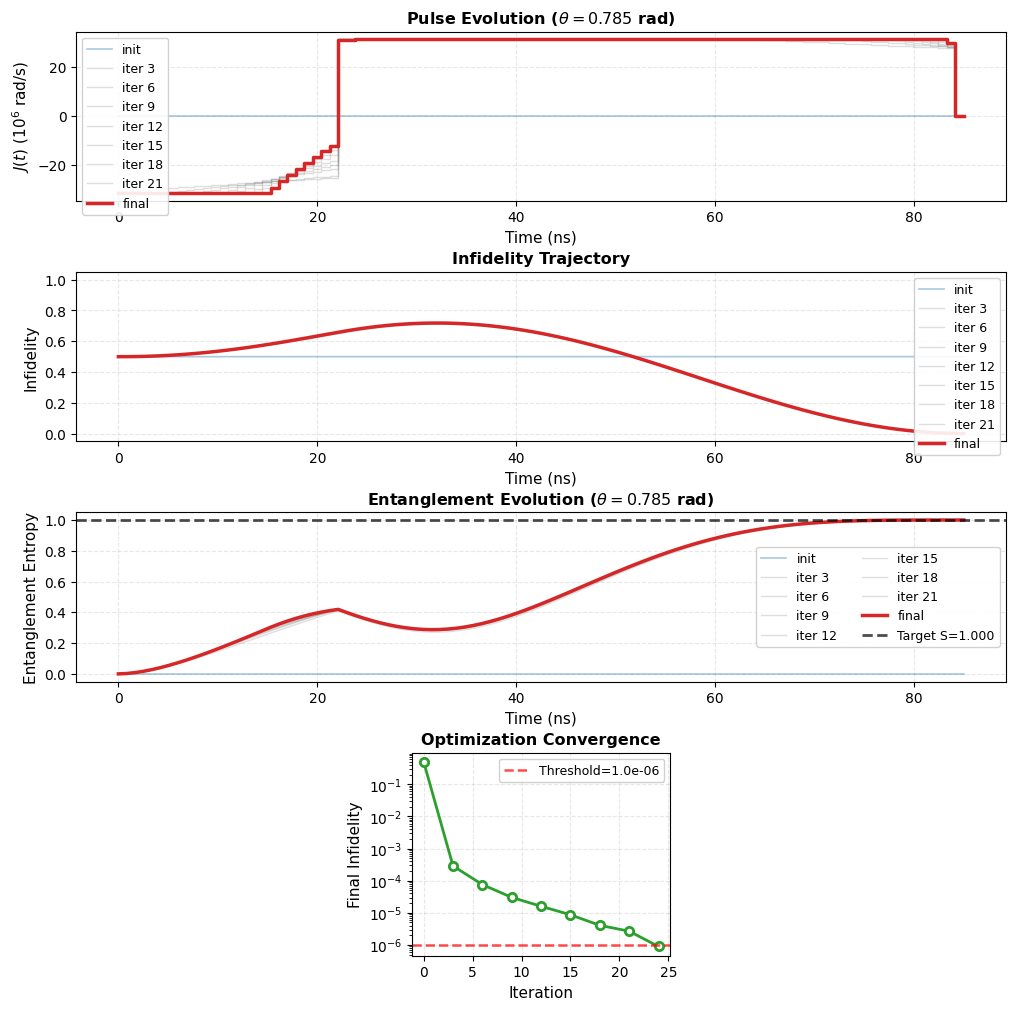

In [20]:
config = SimulationConfig(
    # ---- target / physics ----
    theta=0.25 * np.pi,         # target entangling angle (rad)

    # ---- time discretisation ----
    T_ns=85.0,                  # total evolution time (ns)
    N_SEGMENTS=100,             # number of control segments
    PTS_PER_SEG=1,              # time steps per segment

    # ---- optimisation ----
    max_iter=100,               # max BFGS iterations
    snapshot_every=3,           # iterations between snapshots
    pulse_init_scale=1e-3,      # stddev of initial J amplitudes (MHz)
    seed=None,                  # RNG seed (set for reproducibility)
    infidelity_threshold=1e-6,  # early-stop threshold

    # ---- static field parameters ----
    B1=0.0,                     # MHz
    B2=8.0,                     # MHz (detuning)

    # ---- diagnostics ----
    entanglement_on=True,       # track entanglement entropy during snapshots

    # ---- amplitude bounds ----
    Jmax_mhz=5,          # bound on segment amplitudes (MHz)
)

opt = SQEOptimisation(config)
results = opt.optimise()

plot_optimisation_results(results)